In [5]:
import numpy as np
pallfig3 = np.array([
        [0.08875371253757877, 139703230.64968905],
        [0.10000000000000005, 129821311.34633364],
        [0.1113351053363194, 112333706.57434075],
        [0.12395505680249332, 84248540.37346916],
        [0.14648835726455744, 84030317.70345819],
        [0.15924746909466625, 67718154.47615388],
        [0.18819643787010717, 62881491.36210344],
        [0.21977025491086027, 50618492.537617795],
        [0.2597214220054102, 43759366.516130924],
        [0.2961437631046709, 30542635.585001502],
        [0.33767383432841547, 30480458.654728513],
        [0.38964900819288695, 28313928.35051715],
        [0.4496242650475462, 24486282.691773687],
        [0.5250579684818937, 17084309.552423235],
        [0.6058755398375444, 15869968.43009532],
        [0.6826481084732247, 14747404.931429736],
        [0.7783800741524313, 10293216.070188617],
        [0.919878715168001, 10266554.325262485],
        [0.988140393436075, 7704037.230013012],
        [1.1001471479027738, 5777908.620703499],
        [1.224849985972067, 5370202.5583810415],
        [1.396618273855419, 4324520.42412991],
        [1.5735885676490244, 3242722.560433387],
        [1.8157972645632143, 2610818.147653365],
        [2.0704377436826, 1822267.4049243953],
        [3.8502792425769568, 348451.7871076628],
        [4.286712450465496, 226507.81526437213],
        [4.772615822190868, 210524.76404134053],
        [5.573320131374787, 118525.02625155516],
        [6.991326516475755, 46618.11338031138],
        [8.875371253757882, 11936.677706656546],
        [10.870998355662216, 2297.365033779706],
        [18.375903632975877, 79.07926547254412],
        [22.507725307074534, 20.259688703218043],
        [25.359756413056704, 11.412505662327057],
        [14.648835726455745, 509.3832983098744],
        [15.924746909466633, 248.84132495044994],
], dtype=float)

修正后的拟合结果:
  C = 1.00e+06
  beta = 0.494
  E_tau = 79.6 keV


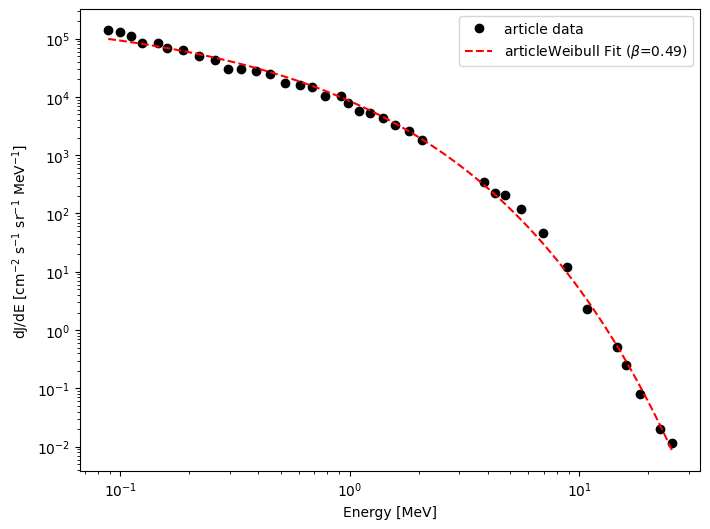

In [6]:
import numpy as np
from scipy.optimize import curve_fit
import matplotlib.pyplot as plt


pallfig3 = pallfig3[np.argsort(pallfig3[:, 0])]

# 1. 提取并还原真实通量 (无需改动)
E_obs = pallfig3[:, 0]
flux_obs_true = pallfig3[:, 1] / 1000.0

# 2. 修改拟合函数：在内部取以 10 为底的对数
def log_weibull_flux(E, C, beta, E_tau):
    flux = C * np.sqrt(E) * (E / E_tau)**(beta - 1) * np.exp(-(E / E_tau)**beta)
    return np.log10(flux)

# 3. 观测数据也取对数
log_flux_obs_true = np.log10(flux_obs_true)

# 4. 初始猜测值和边界 (保持物理真实值)
p0_guess = [3e5, 0.5, 0.081]
bounds = (
    [1e4, 0.2, 0.01],
    [1e7, 1.0, 0.5]
)

# 5. 执行对数空间拟合
popt, pcov = curve_fit(log_weibull_flux, E_obs, log_flux_obs_true, p0=p0_guess, bounds=bounds)

C_fit, beta_fit, E_tau_fit = popt
print(f"修正后的拟合结果:")
print(f"  C = {C_fit:.2e}")
print(f"  beta = {beta_fit:.3f}")
print(f"  E_tau = {E_tau_fit*1000:.1f} keV")

# 6. 绘图 (画图时依然用原本的线性和非对数函数计算，只为视觉呈现)
def weibull_flux_linear(E, C, beta, E_tau):
    return C * np.sqrt(E) * (E / E_tau)**(beta - 1) * np.exp(-(E / E_tau)**beta)

E_smooth = np.logspace(np.log10(min(E_obs)), np.log10(max(E_obs)), 100)
flux_fit_true = weibull_flux_linear(E_smooth, *popt)

plt.figure(figsize=(8, 6))
plt.loglog(E_obs, flux_obs_true, 'ko', label='article data')
plt.loglog(E_smooth, flux_fit_true, 'r--', label=f'articleWeibull Fit ($\\beta$={beta_fit:.2f})')
plt.xlabel('Energy [MeV]')
plt.ylabel('dJ/dE [cm$^{-2}$ s$^{-1}$ sr$^{-1}$ MeV$^{-1}$]')
plt.legend()
plt.show()

[cache] loaded lattice_cache.npz

========== Weibull fit (N(E) space, 0.1-30 MeV) ==========
run           beta     +-   Et[keV]    +-
lat_f0       0.500  0.001      84.5   0.6
lat_f1       0.312  0.005      10.8   1.5
paper        0.500  0.010      81.0   9.0

Observational data fit (user parameterization):
  C = 1.00e+06   (Note: under this parameterization C ≈ paper_C × Et^(beta-1), expected ~1e6)
  beta = 0.494
  E_tau = 79.6 keV

[saved] fig_main.png


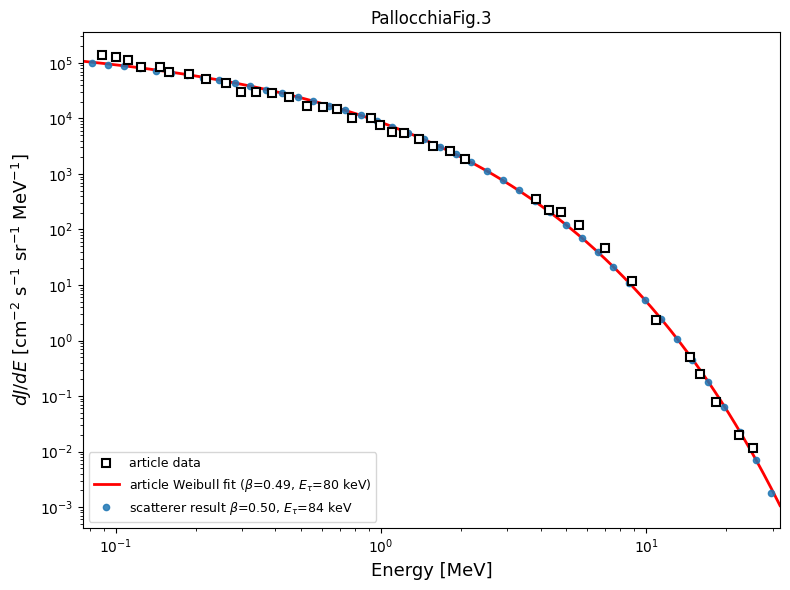

In [ ]:
import os
import time

import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

try:
    from numba import njit, prange
except ImportError:
    raise SystemExit("numba required: pip install numba")

# =====================================================================
# Constants and parameters (consistent with previous weibull_reproduction)
# =====================================================================
MP = 1.67262e-24          # proton mass [g]
C_LIGHT = 2.99792458e10   # [cm/s]
C2 = C_LIGHT * C_LIGHT
ERG2EV = 6.2415e11
WREST = MP * C2
GAMMA_LIM = 1.00001

V_SC = 6.5e6      # scatterer speed = upstream Alfven speed ~65 km/s [cm/s]
ELL = 2.0e7       # grid spacing [cm]
R_ACT = 0.1       # active grid fraction -> lambda_sc = ELL/R = 2e8 cm
NGRID = 601       # number of grid points (periodic boundary; box = 60 mean free paths)
TAU = 950.0       # leaky-box escape time [s]
TMAX_FAC = 19.0
EIN_EV = 1.0e3    # injection energy: solar wind protons ~1 keV
N_MON = 600       # number of monitoring times (linearly spaced)

NP_LATTICE = 3000           # particles for lattice version (per mode)
SEED_LAT_F0, SEED_LAT_F1 = 2024, 2025
FIELD_SEED = 314159         # seed for frozen scatterer field (shared by both f_rand cases)

TMAX = TMAX_FAC * TAU
T_MON = np.linspace(0.0, TMAX, N_MON + 1)[1:]

# =====================================================================
# Common: velocity
# =====================================================================
@njit(inline='always')
def _v_from_W(W):
    gamma = 1.0 + W / WREST
    if gamma > GAMMA_LIM:
        return C_LIGHT * np.sqrt(1.0 - 1.0 / (gamma * gamma))
    return np.sqrt(2.0 * W / MP)


# =====================================================================
# Lattice version: frozen scatterer field (hash) + step-by-step walk  —— Sioulas evolution
# =====================================================================
@njit(inline='always')
def _hash01(ix, iy, iz, fseed):
    """Deterministic hash -> [0,1). Same grid point always returns same value => quenched field."""
    k = (np.uint64(ix)
         + np.uint64(iy) * np.uint64(1000003)
         + np.uint64(iz) * np.uint64(998244353)
         + np.uint64(fseed) * np.uint64(0x9E3779B97F4A7C15))
    k = (k ^ (k >> np.uint64(30))) * np.uint64(0xBF58476D1CE4E5B9)
    k = (k ^ (k >> np.uint64(27))) * np.uint64(0x94D049BB133111EB)
    k = k ^ (k >> np.uint64(31))
    return (k >> np.uint64(11)) * (1.0 / 9007199254740992.0)  # /2^53


@njit(parallel=True)
def simulate_lattice(nP, W0, t_mon, f_rand, seed, fseed):
    """Sioulas lattice walk: periodic boundary, check hash each step, collision kernel as original code.
    Returns Wmon[nP, nM]: kinetic energy [erg] at each monitoring time (recorded before scattering)."""
    nM = t_mon.size
    Wmon = np.empty((nP, nM))
    for ip in prange(nP):
        np.random.seed(seed + ip)
        # initial position/direction
        ix = np.random.randint(0, NGRID)
        iy = np.random.randint(0, NGRID)
        iz = np.random.randint(0, NGRID)
        pdir = np.random.randint(0, 6)   # 0..5: +x,-x,+y,-y,+z,-z
        W = W0
        v = _v_from_W(W)
        t = 0.0
        im = 0
        while im < nM:
            # ---- advance one cell along current direction (periodic boundary) ----
            ax = pdir >> 1
            if (pdir & 1) == 0:
                if ax == 0:
                    ix += 1
                    if ix >= NGRID: ix -= NGRID
                elif ax == 1:
                    iy += 1
                    if iy >= NGRID: iy -= NGRID
                else:
                    iz += 1
                    if iz >= NGRID: iz -= NGRID
            else:
                if ax == 0:
                    ix -= 1
                    if ix < 0: ix += NGRID
                elif ax == 1:
                    iy -= 1
                    if iy < 0: iy += NGRID
                else:
                    iz -= 1
                    if iz < 0: iz += NGRID

            t_next = t + ELL / v
            # record W before scattering for crossed monitoring times
            while im < nM and t_mon[im] <= t_next:
                Wmon[ip, im] = W
                im += 1
            t = t_next
            if im >= nM:
                break

            # ---- whether the arrived grid point is a scatterer (quenched hash) ----
            if _hash01(ix, iy, iz, fseed) < R_ACT:
                sdir = np.random.randint(0, 6)   # scatterer direction: redrawn each collision (A)
                if (sdir >> 1) == (pdir >> 1):
                    isgn = 1 if (sdir & 1) == (pdir & 1) else -1
                else:
                    isgn = 0
                WiTot = W + WREST
                dW = 2.0 * WiTot * ((V_SC * V_SC) / C2
                                    - f_rand * isgn * (V_SC * v) / C2)
                Wf = W + dW
                if Wf < 0.0:
                    Wf = W
                W = Wf
                v = _v_from_W(W)
                pdir = np.random.randint(0, 6)   # new random direction after scattering
    return Wmon


# =====================================================================
# Spectrum construction and fitting
# =====================================================================
def leaky_box_spectrum(Wmon_eV, n_bins=90):
    wts = np.exp(-T_MON / TAU)
    Wflat = Wmon_eV.ravel()
    wflat = np.repeat(wts[None, :], Wmon_eV.shape[0], axis=0).ravel()
    bins = np.logspace(2.5, 7.8, n_bins)
    cnt, edges = np.histogram(Wflat, bins=bins, weights=wflat)
    ctr = np.sqrt(edges[:-1] * edges[1:])
    NE = cnt / np.diff(edges)
    NE /= np.trapezoid(NE, ctr)
    return ctr, NE          # ctr in eV


def fit_weibull_NE(ctr_eV, NE, lo=1e5, hi=3e7):
    def lw(E, lnA, beta, Et):
        x = E / Et
        return lnA + (beta - 1.0) * np.log(x) - x ** beta
    m = (ctr_eV > lo) & (ctr_eV < hi) & (NE > 0)
    popt, pcov = curve_fit(lw, ctr_eV[m], np.log(NE[m]),
                           p0=[np.log(NE[m][0]), 0.5, 8.1e4], maxfev=40000)
    perr = np.sqrt(np.diag(pcov))
    return popt[1], perr[1], popt[2], perr[2]   # beta, dbeta, Et[eV], dEt


def growth_slope(Wmon_eV):
    meanE = Wmon_eV.mean(axis=0)
    msk = T_MON > 2 * TAU
    return np.polyfit(np.log(T_MON[msk]), np.log(meanE[msk]), 1)[0]


def run_cached(fname, runs):
    """runs: dict name -> (func, nP, f_rand, seed). Load from cache if available."""
    if os.path.exists(fname):
        z = np.load(fname)
        print(f"[cache] loaded {fname}")
        return {k: z[k].astype(np.float64) for k in z.files}
    out = {}
    for name, (func, nP, fr, sd) in runs.items():
        t0 = time.time()
        W = func(nP, EIN_EV / ERG2EV, T_MON, fr, sd, FIELD_SEED)
        out[name] = W * ERG2EV
        print(f"[run] {name}: {nP} particles, {time.time()-t0:.0f} s, "
              f"<E>~t^{growth_slope(out[name]):.2f}")
    np.savez_compressed(fname, **{k: v.astype(np.float32) for k, v in out.items()})
    return out


# =====================================================================
# Main
# =====================================================================
if __name__ == "__main__":

    # ---------- Simulation (skip if cached) ----------
    lat = run_cached("lattice_cache.npz", {
        "f0": (simulate_lattice, NP_LATTICE, 0.0, SEED_LAT_F0),
        "f1": (simulate_lattice, NP_LATTICE, 1.0, SEED_LAT_F1),
    })

    # ---------- Spectra and fits ----------
    spec, fits = {}, {}
    for tag, W in [("lat_f0", lat["f0"]), ("lat_f1", lat["f1"])]:
        ctr, NE = leaky_box_spectrum(W)
        spec[tag] = (ctr, NE)
        fits[tag] = fit_weibull_NE(ctr, NE)

    print("\n========== Weibull fit (N(E) space, 0.1-30 MeV) ==========")
    print(f"{'run':<10}{'beta':>8}{'+-':>7}{'Et[keV]':>10}{'+-':>6}")
    for tag in ["lat_f0", "lat_f1"]:
        b, db, Et, dEt = fits[tag]
        print(f"{tag:<10}{b:8.3f}{db:7.3f}{Et/1e3:10.1f}{dEt/1e3:6.1f}")
    print(f"{'paper':<10}{'0.500':>8}{'0.010':>7}{'81.0':>10}{'9.0':>6}")


    pallfig3 = pallfig3[np.argsort(pallfig3[:, 0])]

    E_obs = pallfig3[:, 0]
    flux_obs_true = pallfig3[:, 1] / 1000.0

    def log_weibull_flux(E, C, beta, E_tau):
        flux = C * np.sqrt(E) * (E / E_tau)**(beta - 1) * np.exp(-(E / E_tau)**beta)
        return np.log10(flux)

    log_flux_obs_true = np.log10(flux_obs_true)
    p0_guess = [3e5, 0.5, 0.081]
    bounds = ([1e4, 0.2, 0.01], [1e7, 1.0, 0.5])
    popt, pcov = curve_fit(log_weibull_flux, E_obs, log_flux_obs_true,
                           p0=p0_guess, bounds=bounds)
    C_fit, beta_fit, E_tau_fit = popt
    print(f"\nObservational data fit (user parameterization):")
    print(f"  C = {C_fit:.2e}   (Note: under this parameterization C ≈ paper_C × Et^(beta-1), expected ~1e6)")
    print(f"  beta = {beta_fit:.3f}")
    print(f"  E_tau = {E_tau_fit*1000:.1f} keV")

    def weibull_flux_linear(E, C, beta, E_tau):
        return C * np.sqrt(E) * (E / E_tau)**(beta - 1) * np.exp(-(E / E_tau)**beta)

    #plot1:fig3
    E_smooth = np.logspace(np.log10(0.075), np.log10(32), 300)
    flux_fit_true = weibull_flux_linear(E_smooth, *popt)

    def sim_dJdE(tag, ref_E=0.5):
        ctr, NE = spec[tag]
        E_MeV = ctr / 1e6
        dj = NE * np.sqrt(E_MeV)
        ref = weibull_flux_linear(ref_E, *popt) / np.interp(ref_E, E_MeV, dj)
        return E_MeV, dj * ref

    fig, ax = plt.subplots(figsize=(8, 6))
    ax.loglog(E_obs, flux_obs_true, 'ks', ms=6, mfc='white', mew=1.5, zorder=5,
              label='article data')
    ax.loglog(E_smooth, flux_fit_true, 'r-', lw=2,
              label=f'article Weibull fit ($\\beta$={beta_fit:.2f}, '
                    f'$E_\\tau$={E_tau_fit*1e3:.0f} keV)')
    Em, dj = sim_dJdE("lat_f0")
    m = (Em > 0.075) & (Em < 32)
    bL, _, EtL, _ = fits["lat_f0"]
    ax.loglog(Em[m], dj[m], 'o', ms=4.5, color='C0', alpha=0.85,
              label=f'scatterer result '
                    f'$\\beta$={bL:.2f}, $E_\\tau$={EtL/1e3:.0f} keV')
    ax.set_xlim(0.075, 32)
    ax.set_xlabel('Energy [MeV]', fontsize=13)
    ax.set_ylabel(r'$dJ/dE$ [cm$^{-2}$ s$^{-1}$ sr$^{-1}$ MeV$^{-1}$]', fontsize=13)
    ax.set_title('PallocchiaFig.3')
    ax.legend(fontsize=9, loc='lower left')
    plt.tight_layout()
    plt.savefig('fig_main.png', dpi=160)
    print("\n[saved] fig_main.png")
    plt.show()